# 01 · De estantes a temas

Goodreads no tiene “temas”: tiene **estantes** que cada lector crea (`fantasy`, pero también `to-read`,
`owned`, `read-in-2015`). Este notebook muestra cómo se separaron los estantes temáticos de los
organizativos, cómo quedó la taxonomía y cuánto se puede confiar en las etiquetas resultantes.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from book_topics import MODULE

from common import data_dir, setup_style

setup_style()
d = data_dir(MODULE)
P = d.parent
report = json.loads((P / "resultados" / "metrics.json").read_text())
from book_topics.data import load_shelves
from book_topics.taxonomy import TAU, label_books, load_taxonomy

cand = pd.read_csv(P / "candidatos_estantes.csv")
topics = load_taxonomy(P / "temas.yaml")
shelves = load_shelves(d)
labels = label_books(shelves, topics, TAU)
print(f"{len(cand)} estantes usados en ≥ 100 libros; taxonomía: {len(topics)} temas")

1109 estantes usados en ≥ 100 libros; taxonomía: 40 temas


## 1. El criterio de la spec (Gini) no funcionó

La idea era que un estante temático se *concentra* en pocos libros (Gini alto) y uno organizativo se
reparte (Gini bajo). Pero el Gini resultó medir sobre todo **rareza**:

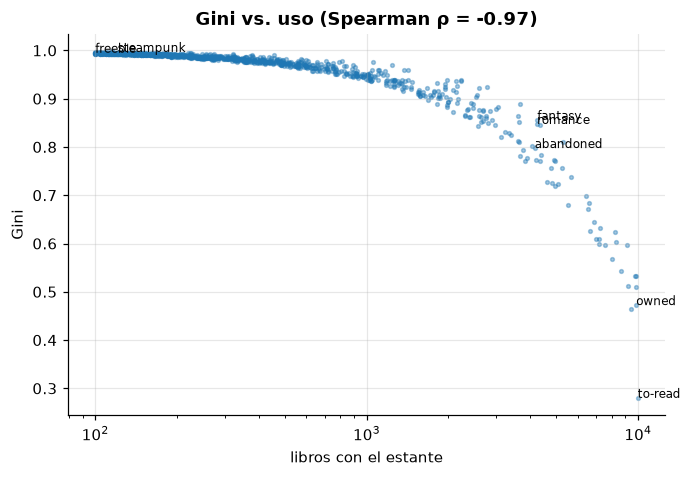

In [2]:
rho = cand.gini.corr(cand.n_books, method="spearman")
fig, ax = plt.subplots()
ax.scatter(cand.n_books, cand.gini, s=6, alpha=0.4)
for name in ("to-read", "owned", "abandoned", "fantasy", "romance", "steampunk", "freebie"):
    row = cand[cand.shelf == name]
    if len(row):
        ax.annotate(name, (row.n_books.item(), row.gini.item()), fontsize=8)
ax.set(
    xscale="log",
    xlabel="libros con el estante",
    ylabel="Gini",
    title=f"Gini vs. uso (Spearman ρ = {rho:.2f})",
);

**Lectura.** Entre los 1 109 estantes usados en ≥ 100 libros, el Gini y el número de libros tienen
Spearman ρ = −0,97: el Gini casi solo dice *cuán raro es el estante*. `fantasy` (0,86) y `abandoned`
(0,80) quedan en la misma zona, y `freebie` (0,995) parece más "temático" que `mystery` (0,89). El
criterio de la spec no sirve para separar temas de organización; se conserva en el código solo para
documentar por qué se descartó.

## 2. Lo que sí separa: correlación con la popularidad del libro

Un estante organizativo (`owned`) crece con cuánta gente estantea el libro; uno temático depende del
contenido. Medida: correlación entre log(1 + conteo del estante) y log(1 + total de estantes del libro).

zona ≥ 0.35 (20 estantes, todos organizativos): read-in-2015, my-books, i-own, ebooks, all-time-favorites, favorite-books, audiobooks, audiobook, kindle, ebook, wish-list, favourites, owned-books, library, to-buy, owned, books-i-own, currently-reading, favorites, to-read


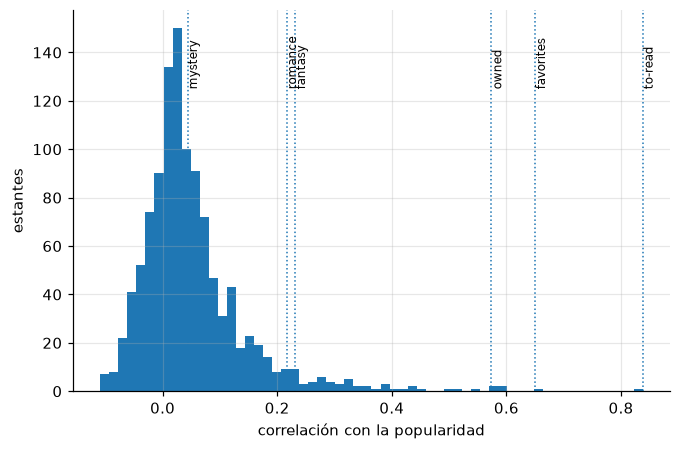

In [3]:
fig, ax = plt.subplots()
ax.hist(cand.corr_popularidad, bins=60)
for name in ("to-read", "owned", "favorites", "fantasy", "romance", "mystery"):
    row = cand[cand.shelf == name]
    if len(row):
        ax.axvline(row.corr_popularidad.item(), ls=":", lw=1)
        ax.annotate(
            name, (row.corr_popularidad.item(), ax.get_ylim()[1] * 0.8), rotation=90, fontsize=8
        )
ax.set(xlabel="correlación con la popularidad", ylabel="estantes")
high = cand[cand.corr_popularidad >= 0.35].shelf.tolist()
print(f"zona ≥ 0.35 ({len(high)} estantes, todos organizativos): {', '.join(high)}")

**Lectura.** La mediana es 0,03 (la mayoría de los estantes no siguen la popularidad del libro). Los 20
estantes con correlación ≥ 0,35 son todos organizativos (`to-read` 0,84, `favorites` 0,65, `owned`
0,57…). Pero la medida no resuelve la zona media: `abandoned` (0,30) está más cerca de `fantasy` (0,23)
y `romance` (0,22) que de `owned`. Por eso el clasificador real es la **lista curada** de `temas.yaml`
(40 temas, 167 estantes): la medida ordena los candidatos y la revisión humana decide.

`★ Insight` — Una métrica que "funciona" en los extremos y falla en el medio es típica de datos de
etiquetado social; cuando el costo de curar a mano es bajo (≈ 1 100 estantes), curar es la opción
honesta, siempre que se documente.

## 3. La taxonomía y el umbral τ

temas por libro: mediana 3, máximo 9, libros sin tema 0


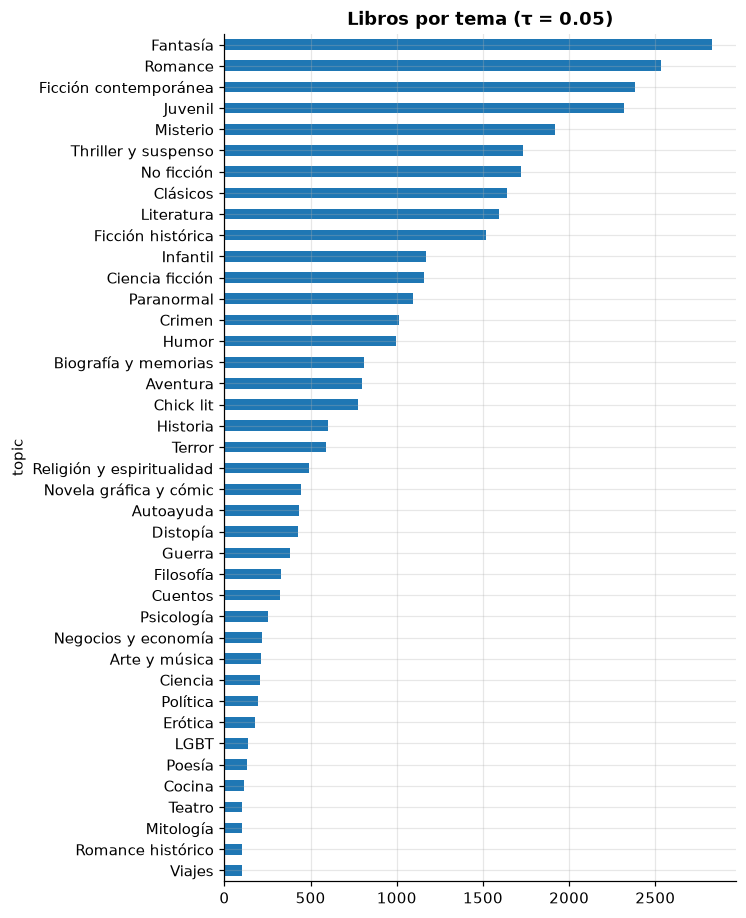

In [4]:
counts = labels.sum().rename(index={t.key: t.nombre for t in topics}).sort_values()
counts.plot.barh(figsize=(6, 10), title=f"Libros por tema (τ = {TAU:.2f})")
n = labels.sum(axis=1)
print(
    f"temas por libro: mediana {n.median():.0f}, máximo {n.max()}, libros sin tema {(n == 0).sum()}"
)

In [5]:
rows = []
for tau in (0.05, 0.10, 0.15, 0.20):
    L = label_books(shelves, topics, tau)
    k = L.sum(axis=1)
    rows.append((tau, k.median(), int((k == 0).sum()), int(L.sum().min())))
pd.DataFrame(rows, columns=["τ", "mediana temas/libro", "libros sin tema", "tema más chico"])

,τ,mediana temas/libro,libros sin tema,tema más chico
0,0.05,3.0,0,100
1,0.10,3.0,0,53
2,0.15,2.0,0,28
3,0.20,2.0,12,9


## 4. ¿Son confiables las etiquetas? Acuerdo con Open Library

300 libros al azar, comparando nuestros temas con los *subjects* de Open Library (catalogación de
bibliotecas) para los 10 temas con equivalente claro.

In [6]:
v = report["validacion_etiquetas"]
kappa = pd.DataFrame(v["kappa_por_tema"]).set_index("topic").sort_values("kappa")
kappa

,kappa,n_ours,n_ol
topic,,,
misterio,0.017791,52,3
romance,0.091941,66,8
autoayuda,0.123201,13,2
juvenil,0.135546,54,6
fantasia,0.145508,76,12
terror,0.190283,18,2
ciencia_ficcion,0.203747,39,5
historia,0.230642,29,14
biografia,0.279449,27,6


**Lectura.** El acuerdo es débil: κ va de 0,02 (misterio) a 0,28 (biografía); poesía (0,33) tiene
solo 5 casos. La columna `n_ol` explica buena parte: Open Library etiqueta mucho menos (misterio: 52
libros nuestros frente a 3 suyos), así que muchos "desacuerdos" son temas que ellos no anotan. Y κ es
inestable con 300 libros: una muestra anterior dio entre 0,13 y 0,47. Las etiquetas de lectores son ruidosas pero no arbitrarias: sirven como verdad de
referencia *aproximada*, y todas las métricas de la Parte A heredan ese techo.